# Used the same dataset used in Practical 2: Question 1. Identify all duplicate cases using prof. Using all observations, find the average and standard deviation for age. Repeat the analysis by first filtering the data set to include one observation for each instructor with a total number of observations restricted to 94. Question 2. Using a bar chart, demonstrate if instructors teaching lower-division courses receive higher average teaching evaluations. Question 3. Plot the relationship between age and teaching evaluation scores. Question 4. Using gender-differentiated scatter plots, plot the relationship between age and teaching evaluation scores. Question 5. Create a scatterplot of age and evaluation scores, differentiated by gender and tenure.

## Question 1: Duplicate Cases and Age Analysis
### Identify all duplicate cases using prof. Using all observations, find the average and standard deviation for age. Repeat the analysis by first filtering the data set to include one observation for each instructor with a total number of observations restricted to 94.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("C:DATA/teaching_ratings_20.csv")

df.head()

,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,yes,39,female,more,0.201,4.3,upper,yes,yes,24,43,1
1,no,38,male,more,-0.431,3.7,upper,yes,yes,17,20,2
2,no,31,male,more,0.857,4.0,upper,yes,yes,35,35,3
3,no,40,female,more,0.467,4.4,upper,yes,yes,40,48,4
4,no,43,female,more,1.207,4.4,upper,yes,yes,42,48,5



## Step 2: Identify duplicate cases using prof

### The prof column identifies each instructor. Since one professor may appear multiple times for different classes, we can check which professor IDs are duplicated.

In [4]:
duplicates = df[df.duplicated(subset='prof', keep=False)]

print(duplicates)

print("Total observations:", len(df))
print("Unique instructors:", df['prof'].nunique())

Empty DataFrame
Columns: [minority, age, gender, credits, beauty, eval, division, native, tenure, students, allstudents, prof]
Index: []
Total observations: 20
Unique instructors: 20


## Step 3: Find the average and standard deviation of age using all observations

In [5]:
mean_age_all = df['age'].mean()
std_age_all = df['age'].std()

print("Average age using all observations:", mean_age_all)
print("Standard deviation using all observations:", std_age_all)

Average age using all observations: 43.7
Standard deviation using all observations: 9.652379035897399


## Step 4: Filter the dataset to one observation per instructor

In [6]:
unique_professors = df.drop_duplicates(subset='prof')

print("Number of observations after filtering:", len(unique_professors))

Number of observations after filtering: 20


## Step 5: Find the average and standard deviation of age for the 94 instructors

In [7]:
mean_age_unique = unique_professors['age'].mean()
std_age_unique = unique_professors['age'].std()

print("Average age for unique instructors:", mean_age_unique)
print("Standard deviation for unique instructors:", std_age_unique)

Average age for unique instructors: 43.7
Standard deviation for unique instructors: 9.652379035897399


## Conclusion for Question 1 The dataset contains multiple observations for some instructors because a professor may teach more than one course. When all observations are used, instructors who appear multiple times have a greater influence on the average age. After removing duplicate cases using the prof variable, the dataset is reduced to 94 unique instructors. Comparing the mean and standard deviation in both cases helps us understand the difference between analysing all course observations and analysing each instructor only once.

# Question 2: Lower-Division Courses and Teaching Evaluations
## Using a bar chart, demonstrate if instructors teaching lower-division courses receive higher average teaching evaluations.

## Step 1: Calculate the average evaluation score by division

In [8]:
average_eval = df.groupby('division')['eval'].mean()

print(average_eval)

division
lower    3.800000
upper    3.926316
Name: eval, dtype: float64


## Step 2: Create the bar chart

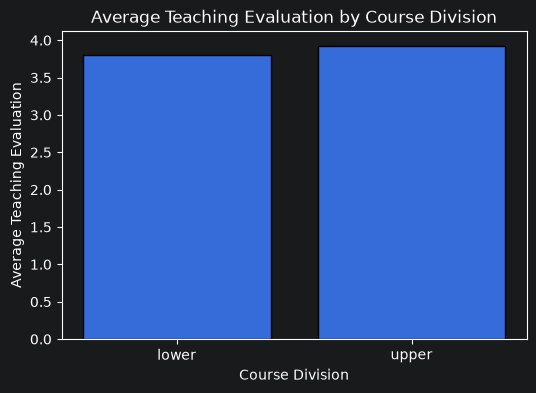

In [9]:
plt.figure(figsize=(6, 4))

plt.bar(
    average_eval.index,
    average_eval.values,
    edgecolor='black'
)

plt.xlabel("Course Division")
plt.ylabel("Average Teaching Evaluation")
plt.title("Average Teaching Evaluation by Course Division")

plt.show()

# Question 3: Plot the Relationship Between Age and Teaching Evaluation Scores

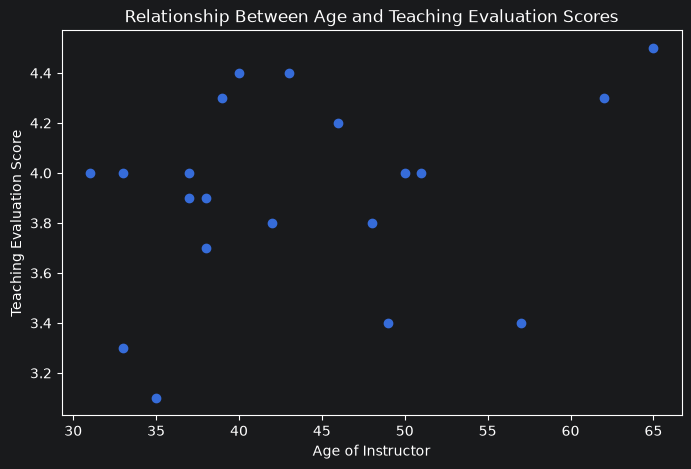

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(df['age'], df['eval'])

plt.xlabel("Age of Instructor")
plt.ylabel("Teaching Evaluation Score")
plt.title("Relationship Between Age and Teaching Evaluation Scores")

plt.show()

## A scatter plot is used because both age and evaluation score are numerical variables. Each point represents an observation in the dataset. The graph helps us observe whether teaching evaluation scores tend to increase, decrease, or show no clear pattern as the age of instructors changes.


# Question 4: Gender-Differentiated Scatter Plot

## Using gender-differentiated scatter plots, plot the relationship between age and teaching evaluation scores.

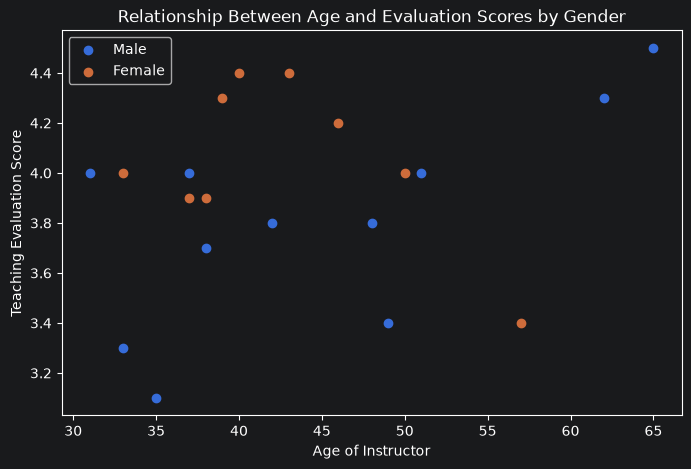

In [11]:
plt.figure(figsize=(8, 5))

male = df[df['gender'] == 'male']
female = df[df['gender'] == 'female']

plt.scatter(male['age'], male['eval'], label='Male')
plt.scatter(female['age'], female['eval'], label='Female')

plt.xlabel("Age of Instructor")
plt.ylabel("Teaching Evaluation Score")
plt.title("Relationship Between Age and Evaluation Scores by Gender")

plt.legend()
plt.show()

## The data is divided into male and female instructors, and separate scatter points are plotted for each gender. This makes it possible to compare the relationship between age and teaching evaluation scores for male and female instructors.

# Question 5: Scatter Plot of Age and Evaluation Scores by Gender and Tenure
## Create a scatterplot of age and evaluation scores, differentiated by gender and tenure.

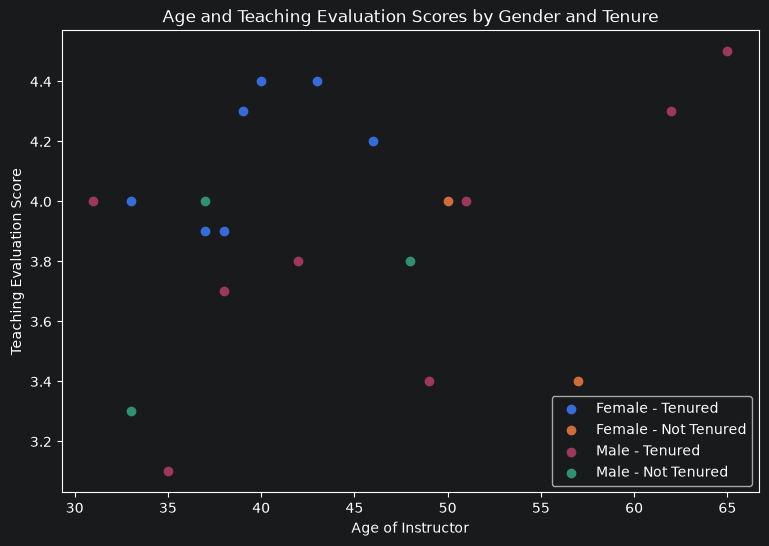

In [12]:
plt.figure(figsize=(9, 6))

for gender in df['gender'].unique():
    for tenure in df['tenure'].unique():

        group = df[
            (df['gender'] == gender) &
            (df['tenure'] == tenure)
        ]

        plt.scatter(
            group['age'],
            group['eval'],
            label=f"{gender.title()} - {'Tenured' if tenure == 'yes' else 'Not Tenured'}"
        )

plt.xlabel("Age of Instructor")
plt.ylabel("Teaching Evaluation Score")
plt.title("Age and Teaching Evaluation Scores by Gender and Tenure")

plt.legend()
plt.show()

## The scatter plot shows the relationship between instructors' age and teaching evaluation scores while separating the observations according to both gender and tenure status. Each group is shown separately in the legend, making it easier to compare the patterns among male and female instructors and between tenured and non-tenured professors.